# Cookie Cats A/B Test

## Exploratory Data Analysis

**Notebook:** 02_cleaning_eda.ipynb  
**Phase:** 1 — Data Loading, Cleaning & Exploration  
**Source:** BigQuery table `cookie_cats.clean_cookie_cats` (90,189 players), built by Section 3 of `sql/01_data_preparation.sql`  
**Author:** Taofeek Salami  
**Date:** 2026-10-20  

## Purpose

Explore the clean data for all players together: how the retention flags combine, how game rounds are distributed, and how retention varies with the number of rounds played. Cleaning was done in SQL and is recorded in `docs/cleaning_log.md`; this notebook changes no data.

The two versions are not compared here. That is Phase 2 (description) and Phase 3 (testing). Observations describe patterns, not causes. Game rounds were recorded after players were assigned to a version, so any pattern involving them is descriptive only.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt   # charts
import numpy as np                # numeric helpers (bin edges)
import pandas as pd               # tables in Python
from dotenv import load_dotenv
from google.cloud import bigquery

## Configuration

Settings come from `.env`. Chart colours are set once here so every chart uses the same style.

In [2]:
PROJECT_ROOT = Path.cwd().resolve().parent
load_dotenv(PROJECT_ROOT / ".env")

PROJECT_ID = os.environ["GCP_PROJECT_ID"]
DATASET = os.environ["BQ_DATASET"]
LOCATION = os.environ["BQ_LOCATION"]

CLEAN_TABLE = f"{PROJECT_ID}.{DATASET}.clean_cookie_cats"
EXPECTED_ROWS = 90_189

client = bigquery.Client(project=PROJECT_ID, location=LOCATION)

# One colour for single-series charts; text and grid in neutral greys so the
# data marks stand out.
SERIES_COLOUR = "#2a78d6"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID_COLOUR = "#e4e3df"

plt.rcParams.update({
    "axes.spines.top": False,       # no box around the plot
    "axes.spines.right": False,
    "axes.edgecolor": GRID_COLOUR,
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.titlecolor": TEXT_PRIMARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "axes.grid": True,
    "axes.grid.axis": "y",          # horizontal gridlines only
    "grid.color": GRID_COLOUR,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,         # gridlines behind the bars
})

## Load the clean table

The table is small (90,189 rows, 7 columns), so it is read into pandas in one query. The row count is checked against the validated clean table.

In [3]:
# SELECT * is acceptable here because the table is small and every column is
# used. On large tables, select only the columns you need: BigQuery charges by
# the columns scanned.
df = client.query(f"SELECT * FROM `{CLEAN_TABLE}`").to_dataframe()

assert len(df) == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS} rows, got {len(df)}"
print("Rows:", len(df))
df.dtypes

Rows: 90189


userid                     Int64
version                      str
sum_gamerounds             Int64
retention_1              boolean
retention_7              boolean
is_extreme_gamerounds    boolean
is_zero_gamerounds       boolean
dtype: object

## Retention flags

Share of all players retained at day 1 and day 7, and how the two flags combine.

In [4]:
# The mean of a true/false column is the share of rows that are true.
retention_summary = pd.DataFrame({
    "retained_players": [df["retention_1"].sum(), df["retention_7"].sum()],
    "share_of_players_pct": [df["retention_1"].mean() * 100, df["retention_7"].mean() * 100],
}, index=["day 1", "day 7"]).round(2)
display(retention_summary)

# crosstab counts every combination of the two flags; margins=True adds totals.
pd.crosstab(df["retention_1"], df["retention_7"], margins=True, margins_name="total")

,retained_players,share_of_players_pct
day 1,40153,44.52
day 7,16781,18.61


retention_7,False,True,total
retention_1,,,
False,46437,3599,50036
True,26971,13182,40153
total,73408,16781,90189


## Game rounds distribution

Percentiles, then a histogram. The histogram stops at 250 rounds so the shape of the bulk of the data is visible; players above 250 are counted separately rather than hidden.

In [5]:
rounds = df["sum_gamerounds"]

percentiles = rounds.quantile([0.25, 0.50, 0.75, 0.95, 0.99]).rename("rounds")
display(percentiles.to_frame())

print("Mean:", round(rounds.mean(), 2))
print("Players with 0 rounds:", (rounds == 0).sum())
print("Players above 250 rounds:", (rounds > 250).sum())

,rounds
0.25,5.0
0.50,16.0
0.75,51.0
0.95,221.0
0.99,493.0


Mean: 51.87
Players with 0 rounds: 3994
Players above 250 rounds: 3708


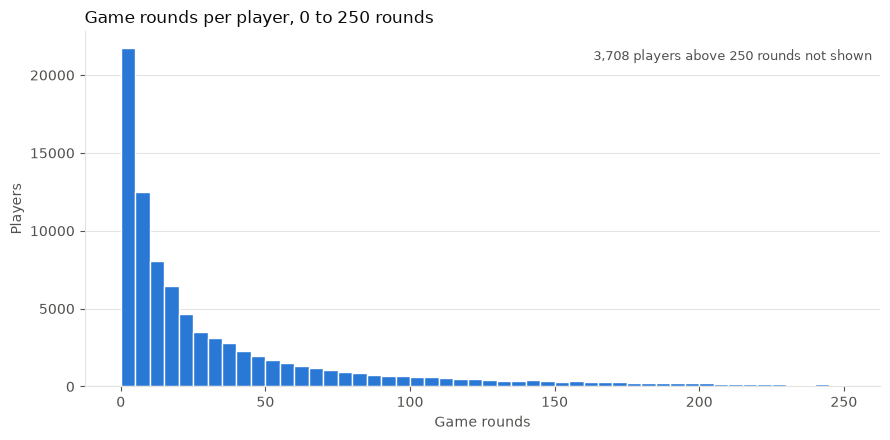

In [6]:
CUTOFF = 250
above_cutoff = (rounds > CUTOFF).sum()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(
    rounds[rounds <= CUTOFF],
    bins=np.arange(0, CUTOFF + 5, 5),   # one bar per 5 rounds
    color=SERIES_COLOUR,
    edgecolor="white",                  # thin gap between bars
    linewidth=1,
)
ax.set_title("Game rounds per player, 0 to 250 rounds", loc="left")
ax.set_xlabel("Game rounds")
ax.set_ylabel("Players")
ax.text(
    0.99, 0.95, f"{above_cutoff:,} players above {CUTOFF} rounds not shown",
    transform=ax.transAxes, ha="right", va="top", color=TEXT_SECONDARY, fontsize=9,
)
plt.tight_layout()
plt.show()

## Retention by game-round band (all players)

Players grouped by the number of rounds they played, with the share retained at day 1 and day 7 in each band. This describes how retention and play go together; it does not show that one causes the other.

In [7]:
# pd.cut puts each player into a band. Each bin edge is the upper end of a band:
# (-1, 0] is exactly 0 rounds, (0, 9] is 1 to 9 rounds, and so on.
bins = [-1, 0, 9, 29, 99, 499, np.inf]
labels = ["0", "1–9", "10–29", "30–99", "100–499", "500+"]
df["rounds_band"] = pd.cut(df["sum_gamerounds"], bins=bins, labels=labels)

band_summary = (
    df.groupby("rounds_band", observed=True)
      .agg(
          players=("userid", "count"),
          retained_day_1_pct=("retention_1", "mean"),
          retained_day_7_pct=("retention_7", "mean"),
      )
)
band_summary[["retained_day_1_pct", "retained_day_7_pct"]] *= 100
band_summary = band_summary.round(1)
display(band_summary)

,players,retained_day_1_pct,retained_day_7_pct
rounds_band,,,
0,3994,2.2,0.7
1–9,30243,11.6,1.8
10–29,22683,43.6,7.7
30–99,20753,74.2,26.8
100–499,11656,89.5,69.3
500+,860,97.4,95.6


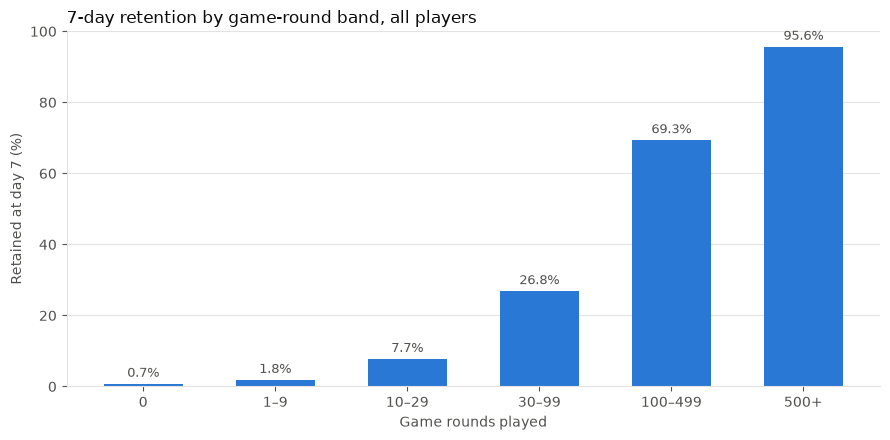

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(
    band_summary.index.astype(str),
    band_summary["retained_day_7_pct"],
    color=SERIES_COLOUR,
    width=0.6,
)
# Value labels on each bar: six bars, so labels help rather than clutter.
ax.bar_label(bars, fmt="%.1f%%", color=TEXT_SECONDARY, fontsize=9, padding=3)
ax.set_title("7-day retention by game-round band, all players", loc="left")
ax.set_xlabel("Game rounds played")
ax.set_ylabel("Retained at day 7 (%)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

## Observations

- 44.52% of all players were retained at day 1 and 18.61% at day 7 (both versions together).
- Game rounds are heavily right-skewed: the largest group played 0–4 rounds, counts fall steadily as rounds increase, and 3,708 players played more than 250 rounds.
- Retention rises across every game-round band: 7-day retention goes from 0.7% for players with 0 rounds to 95.6% for players with 500 or more, and 1-day retention from 2.2% to 97.4%.
- This is an association, not evidence of cause. If game rounds are counted over the 14 days after install, players who return later have more days in which to play, so part of the association may come from how the two measures were recorded.
- Band sizes vary from 860 players (500+) to 30,243 (1–9). The bands were chosen for exploration and are not a finding in themselves.
- Percentiles, retained counts and the retention flag table match the SQL results in `sql/01_data_preparation.sql`.